# Programming and Data Bases - Python Final Assignment
# Analysis and Classification Of the Spanish Congreso

Universitat Politècnica de Catalunya · Barcelona Tech - UPC

Statistical Programming and Data Bases 
Fall Semester 2024/25

Tobias Damaske (C3FPF7R35)

In [3]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip available: 22.3 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import ndimage,misc

# Suppress specific warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


C:\Users\tobif\AppData\Local\Temp\ipykernel_5412\2703737909.py:6: DeprecationWarning: scipy.misc is deprecated and will be removed in 2.0.0
  from scipy import ndimage,misc


## Congreso Meta Data Analysis
<i style="color: grey;">_1. Look at the metadata file, which is the propotion of male/females? which is the most common male name? and female name? which is the size of the dataset? How many individuals we have for each political party?_

Let's load the dataset and have a look at its structure. 
Note that I changed the csv minimally by removing the " " after "Party " so that it can be read properly.

In [5]:
data = pd.read_csv('../datasets/db/index.csv', sep=';', encoding='utf-8') 


In [6]:
print(data.columns)
print(data.shape)
print(data.info())
data.head(n=5)


Index(['Num', 'Name', 'Surname', 'Gender', 'Party'], dtype='object')
(348, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Num      348 non-null    int64 
 1   Name     348 non-null    object
 2   Surname  348 non-null    object
 3   Gender   348 non-null    object
 4   Party    348 non-null    object
dtypes: int64(1), object(4)
memory usage: 13.7+ KB
None


,Num,Name,Surname,Gender,Party
0,321,Manuel,Marín González,H,GS
1,251,Carme,Chacón Piqueras,M,GS
2,132,Jordi,Vilajoana Rovira,H,GC-CiU
3,181,Gabriel,Cisneros Laborda,H,GP
4,154,Ignacio,Gil Lázaro,H,GP


So we see that we have five columns, of which all are categorical values. Let's see how complete the data is.

In [7]:
print(f"missing values:\n{data.isna().sum()}") # all good. 
print(f"duplicate rows: {data.duplicated().sum()}") # all good.

missing values:
Num        0
Name       0
Surname    0
Gender     0
Party      0
dtype: int64
duplicate rows: 0


In [8]:

# Calculate the number of unique names
unique_names = data['Name'].nunique()
print(f"Number of unique names: {unique_names}")

# Calculate most common names
name_distribution = data['Name'].value_counts().sort_values(ascending=False)
print("Most common names:")
print(name_distribution.head(n=6))

# Calculate gender distribution
gender_distribution = data['Gender'].value_counts()
print("Gender distribution:")
print(gender_distribution)

# Calculate party distribution
party_distribution = data['Party'].value_counts()
print("Party distribution:")
print(party_distribution)



Number of unique names: 244
Most common names:
Name
José           7
Carmen         7
Antonio        6
Jordi          6
Francisco      5
Jesús          5
Name: count, dtype: int64
Gender distribution:
Gender
H     223
M     125
Name: count, dtype: int64
Party distribution:
Party
GS              164
GP              146
GC-CiU           10
GER-ERC           8
GV                7
GIV-IU-ICV        5
GMx               5
GCC               3
Name: count, dtype: int64


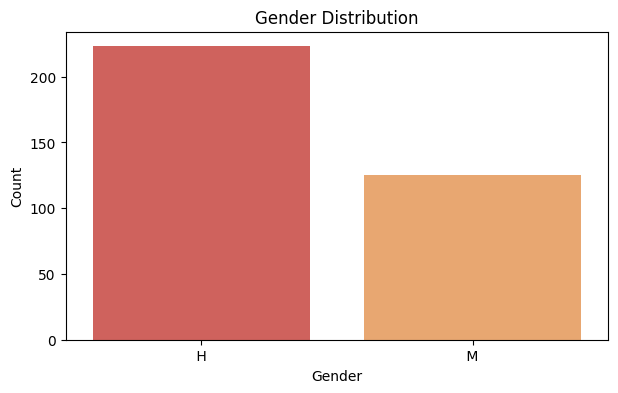

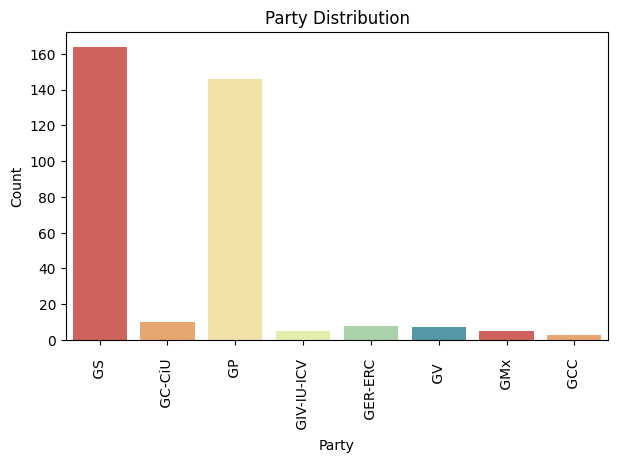

C:\Users\tobif\AppData\Local\Temp\ipykernel_5412\2904666136.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_20_name_gender_counts['TotalCount'] = top_20_name_gender_counts.groupby('Name')['Count'].transform('sum')


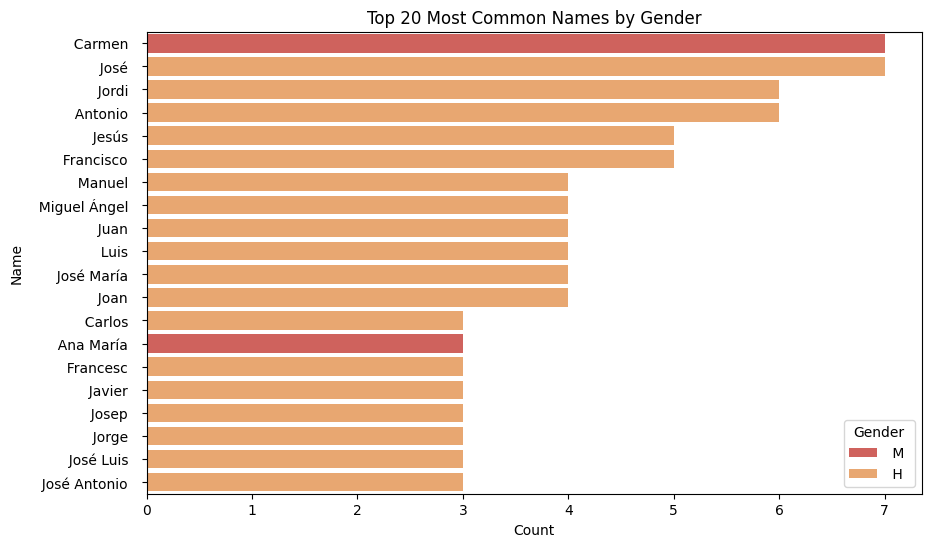

In [9]:

spanish_palette = sns.color_palette("Spectral")

# Display gender distribution as a bar plot
plt.figure(figsize=(7, 4))
sns.countplot(x='Gender', data=data, palette=spanish_palette)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Display party distribution as a bar plot
plt.figure(figsize=(7, 4))
sns.countplot(x='Party', data=data, palette=spanish_palette)
plt.title('Party Distribution')
plt.xlabel('Party')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

# Plot the most common 20 names
name_gender_counts = data.groupby(['Name', 'Gender']).size().reset_index(name='Count')

top_20_names = name_gender_counts.groupby('Name')['Count'].sum().nlargest(20).index
top_20_name_gender_counts = name_gender_counts[name_gender_counts['Name'].isin(top_20_names)]

top_20_name_gender_counts['TotalCount'] = top_20_name_gender_counts.groupby('Name')['Count'].transform('sum')
top_20_name_gender_counts = top_20_name_gender_counts.sort_values(by='TotalCount', ascending=False)

# Plot the most common 20 names colored by gender
plt.figure(figsize=(10, 6))
sns.barplot(x='Count', y='Name', hue='Gender', data=top_20_name_gender_counts, palette=spanish_palette, order=top_20_name_gender_counts['Name'].unique())
plt.title('Top 20 Most Common Names by Gender')
plt.xlabel('Count')
plt.ylabel('Name')
plt.show()

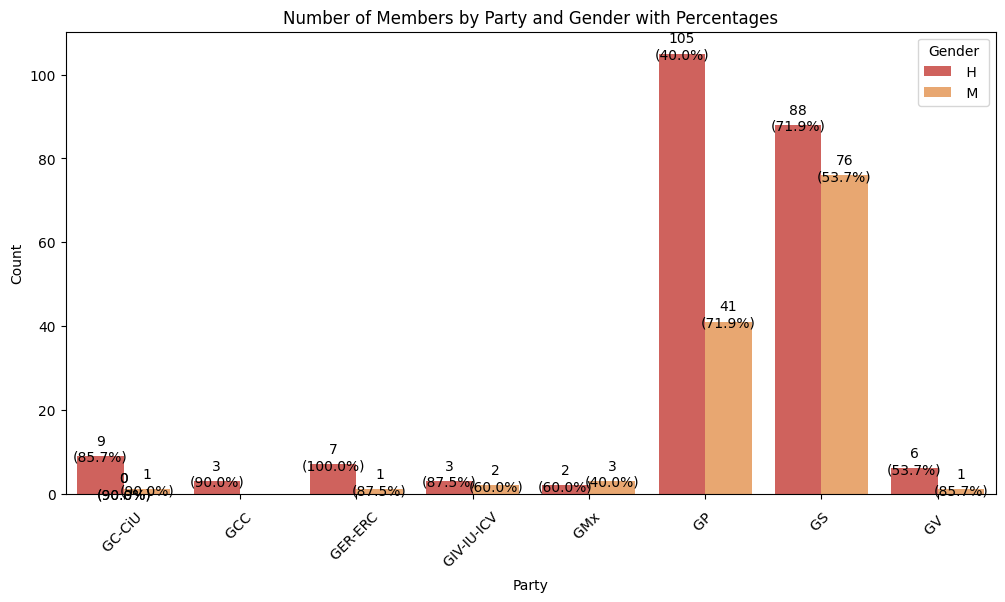

In [7]:
grouped = data.groupby(['Party', 'Gender']).size().reset_index(name='Count')

# Calculate the percentage for each gender per party
grouped['Percentage'] = grouped.groupby('Party')['Count'].apply(lambda x: 100 * x / x.sum()).values

# Plot the absolute values and add percentages as labels
plt.figure(figsize=(12, 6))
barplot = sns.barplot(data=grouped, x='Party', y='Count', hue='Gender', palette=spanish_palette)

# Add percentages as labels
for p in barplot.patches:
    height = p.get_height()
    party = p.get_x() // 1  # Get the integer part of the x position
    gender = p.get_facecolor()
    percentage = grouped[(grouped['Party'] == barplot.get_xticklabels()[int(party)].get_text()) & (grouped['Gender'] == barplot.get_legend().get_texts()[int(gender[0])].get_text())]['Percentage'].values[0]
    barplot.annotate(f'{height:.0f}\n({percentage:.1f}%)',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                     textcoords='offset points')

plt.title('Number of Members by Party and Gender with Percentages')
plt.xlabel('Party')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.show()

## Looking at the Pictures


### Running the code to get the images and to compute the mean pixel values

In [10]:

class Diputado(object):
    def __init__(self,ind,fileRoot="./"):
        self.name=""
        self.surname=""
        self.ind=ind
        self.picfile=""
        self.party=""
        self.gender=""
        self.fileRoot=fileRoot
        self.ext="c.jpg" 
    def setName(self,name):
        self.name=name
    def setSurname(self,surname):
        self.surname=surname
    def setParty(self,party):
        self.party=party
    def setGender(self,gender):
        self.gender=gender
    def getName(self):
        return self.name
    def getSurname(self):
        return self.surname
    def getInd(self):
        return self.ind
    def getPicfile(self):
        return self.fileRoot + str(self.ind) + self.ext
    def getParty(self):
        return self.party
    def getGender(self):
        return self.gender
       

Parlament class

Let's define a very simple Parlament object, where we store the diputados objects. From this class, we have to be able to get information from the parlament.

In [11]:
class Parlament(object):
    def __init__(self):
        self.elements=[]
        self.inds=[]
        self.ndips=0
    def add(self, diputado):
        self.elements.append(diputado)
        self.inds.append(diputado.getInd())
        self.ndips +=1
    def getInds(self):
        return [self.elements[i].getInd() for i in range(self.ndips)]
    def len(self):
        return len(self.elements)
    def __getitem__(self, key):
        if isinstance(key, slice):
            indices = key.indices(self.ndips)
            return [self[ii] for ii in xrange(*key.indices(self.len()))] 
        else:
            return self.elements[key]
    def getName(self,key):
        return self.elements[key].getName()
        

In [12]:
# just because my wd was playing a bit weird
import os
# os.getcwd() 
# os.chdir('Z:/MSc Data Science Economics Universitat Barcelona/UPC - PDB Programming and Databases/Final Assignment Python')

Because the Spanish letters need include a lot of special characters, we need to add the `utf8` encoding when reading the csv file. 

In [13]:
import csv
with open('../datasets/db/index.csv','r', encoding="utf8") as csvfile:
    r = csv.reader(csvfile, delimiter=';')
    next(r)
    p = Parlament()
    for row in r:
        n = Diputado(int(row[0]),"../datasets/db/db/")
        n.setName(row[1].strip())
        n.setSurname(row[2].strip())
        n.setGender(row[3].strip())
        n.setParty(row[4].strip())
        p.add(n)

In [14]:
p.len()
p[99].getPicfile()

'db/db/91c.jpg'

In [15]:
p[99].name

'Francisco Xavier'

Let's create a dataset of the analysis.


'Joan | Tardà i Coma | H'

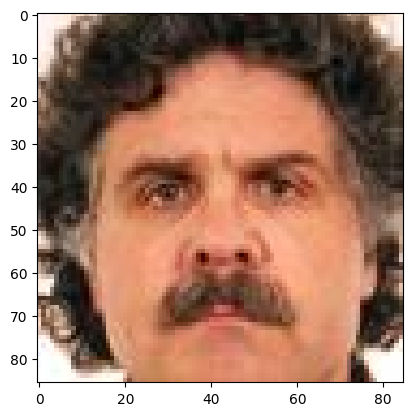

In [16]:

idip = 129
I = plt.imread(p[idip].getPicfile())
plt.imshow(I)
np.shape(I)
' | '.join([p[idip].getName(), p[idip].getSurname(), p[idip].getGender()])

86
(86, 85)


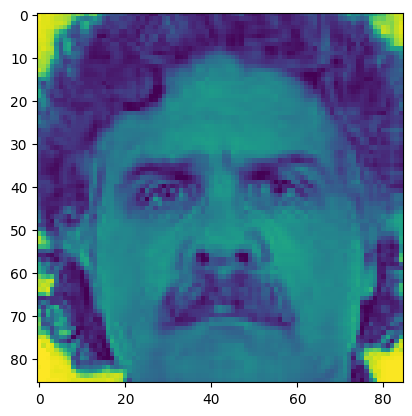

In [17]:
print(len(plt.imread(p[idip].getPicfile()).mean(axis=2)))
I_lum = I[: ,: , 2]
plt.imshow(I_lum)
I[: ,: , 2]
print(plt.imread(p[idip].getPicfile()).mean(axis=2).shape)

(86, 85)

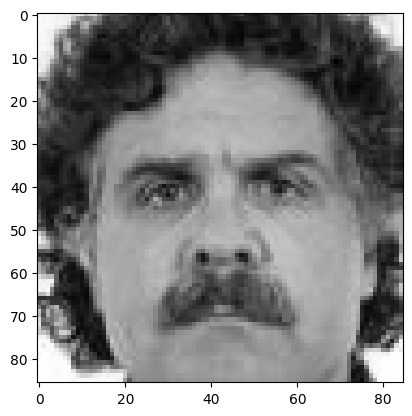

In [16]:
I = plt.imread(p[idip].getPicfile()).mean(axis=2)
img=plt.imshow(I)
img.set_cmap('gray')
Is=I.shape
Is

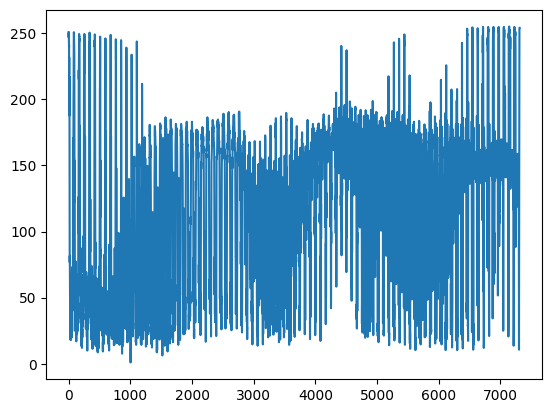

In [17]:
Iv = np.reshape(I,np.prod(Is)) # same as np.ravel()
plt.plot(Iv)

Let's stack all images to an array and create a couple of dependent variables.

In [ ]:
# X=np.array([ plt.imread(d.getPicfile()).mean(axis=2).ravel()
#              for d in p])
# Yg = np.array([ d.getGender() for d in p])
# Yp = np.array([ d.getParty() for d in p])
# Yp[0:5],Yg[0:5],X.shape

(array(['GS', 'GS', 'GC-CiU', 'GP', 'GP'], dtype='<U10'),
 array(['H', 'M', 'H', 'H', 'H'], dtype='<U1'),
 (348, 7310))

In [ ]:
# # Save the arrays to disk to skip previous step
# np.save('../datasets/X.npy', X)
# np.save('../datasets/Yg.npy', Yg)
# np.save('../datasets/Yp.npy', Yp)

### Loading the data array (flattened)

In [18]:
# I saved the arrays to disk, so I can load them back in the future and avoid long running times
X = np.load('../datasets/X.npy')
Yg = np.load('../datasets/Yg.npy')
Yp = np.load('../datasets/Yp.npy')

# Verify the loaded data
print(Yp[0:5], Yg[0:5], X.shape)

['GS' 'GS' 'GC-CiU' 'GP' 'GP'] ['H' 'M' 'H' 'H' 'H'] (348, 7310)


In [19]:
print(len(X[0]))
print(85*86)
print(len(X))

7310
7310
348


So now we have an array with 348 rows and 7310 coluns/pixels. Which is the 85x86 pixels flattened out. In other words, we have a dataset with 348 entries and 7310 features. That is a lot so trying to find a way to group them or to do feature reduction might be a good approach here -> kmeans.

In [20]:
# Create a DataFrame from X in case I need it later
df_X = pd.DataFrame(X)

# Add Gender and Party columns
df_X['Gender'] = Yg
df_X['Party'] = Yp

print(df_X.head(2))
df_X.columns

            0           1           2           3           4           5  \
0  251.333333  251.000000  243.666667  250.333333  220.000000  155.666667   
1  253.000000  253.666667  255.000000  254.333333  253.333333  253.333333   

            6           7           8           9  ...        7302   7303  \
0  148.000000  134.666667  152.333333  159.666667  ...  255.000000  255.0   
1  254.666667  253.000000  252.333333  248.333333  ...  122.333333  121.0   

         7304        7305        7306        7307        7308        7309  \
0  255.000000  255.000000  255.000000  255.000000  255.000000  255.000000   
1  133.333333   95.666667  128.666667  144.333333  109.333333  111.333333   

   Gender  Party  
0       H     GS  
1       M     GS  

[2 rows x 7312 columns]


Index([       0,        1,        2,        3,        4,        5,        6,
              7,        8,        9,
       ...
           7302,     7303,     7304,     7305,     7306,     7307,     7308,
           7309, 'Gender',  'Party'],
      dtype='object', length=7312)

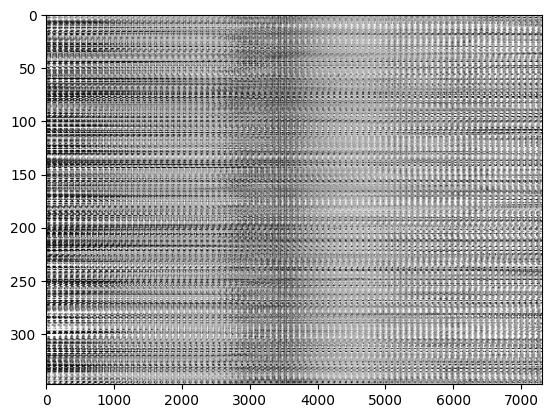

In [21]:
plt.figure()
plt.imshow(X,aspect='auto')
plt.set_cmap('gray')


### Solving the questions:

#### <i style="color: grey;">_2. Compute the mean representative and plot the image corresponding to the mean representative (dataset provided below)_

In [22]:
X.mean(axis=0)

array([232.86494253, 230.53831418, 228.03065134, ..., 212.55076628,
       215.04214559, 217.44444444])

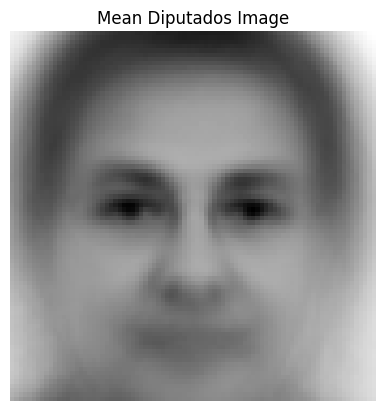

In [23]:
mean_representative = X.mean(axis=0)

image_shape = (86, 85)  
mean_image = mean_representative.reshape(image_shape)

plt.imshow(mean_image, cmap='gray') # gray is always used, since that is the color of the images - I reckon I could also use other color palettes
plt.title('Mean Diputados Image')
plt.axis('off')
plt.show()

#### <i style="color:grey">3. Compute the standard deviation and plot the corresponding image.

In [24]:
X.std(axis=0)

array([52.60725185, 55.39675312, 58.32960869, ..., 76.16057541,
       74.77581743, 72.16625595])

Of course, the values of the standard deviation will be much lower than the means (hopefully), so we can expect the image to be much darker, especially in those parts which are the same for all representatives, namely, the corners and the face.

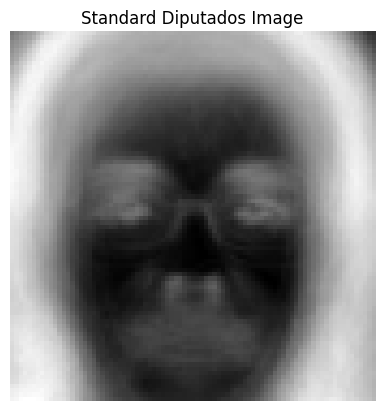

In [25]:
std_representative = X.std(axis=0)

image_shape = (86, 85)  
std_image = std_representative.reshape(image_shape)

plt.imshow(std_image, cmap='gray')
plt.title('Standard Diputados Image')
plt.axis('off')
plt.show()

#### <i style="color:grey">4. Run a k-means clustering and split the representatives' data into 10 groups. Plot the full set of images for two groups of your choice. 


Out of interest sake, I plotted a dendogram to see if having 10 groups makes sense. Depending on where you threshold, 4, 8 and yes, even 10 clusters might make sense for hierarchical clustering like kmeans.

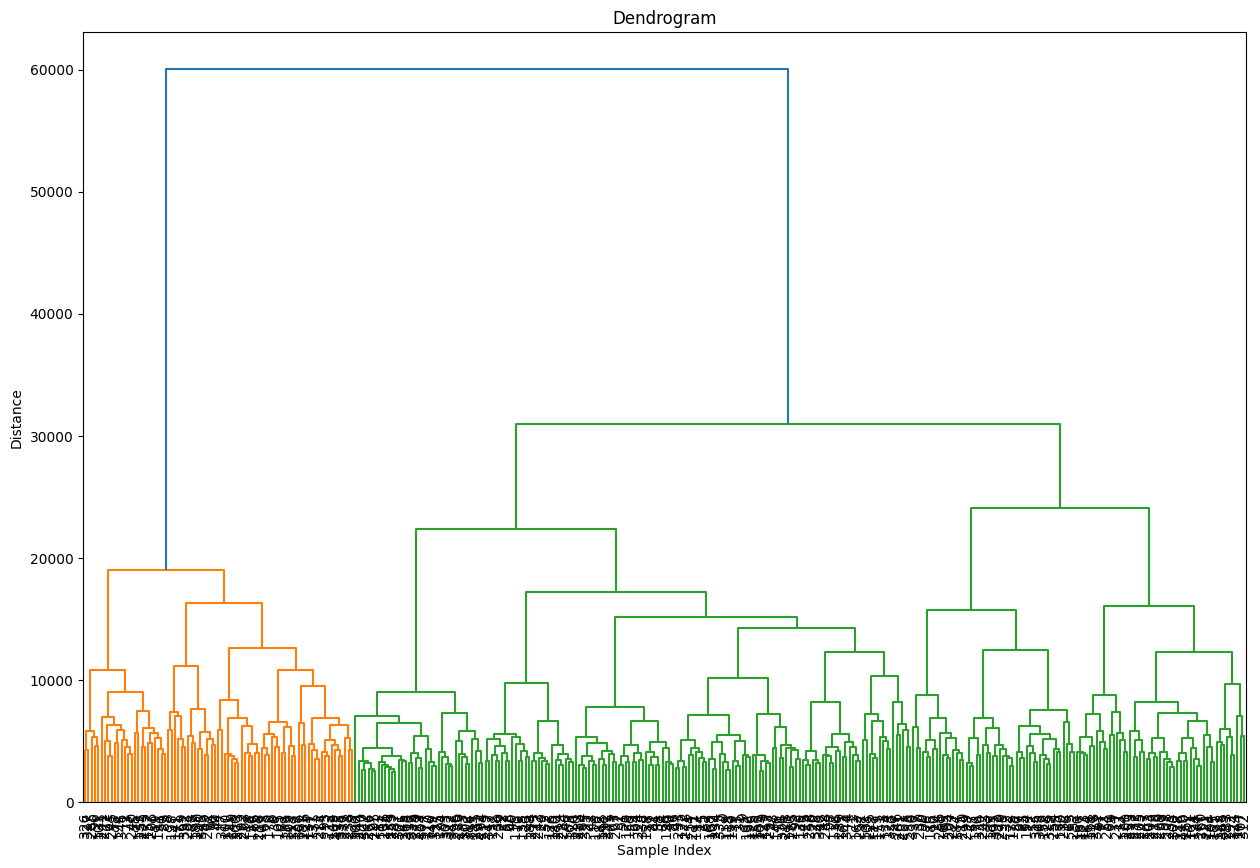

In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Compute the linkage matrix
Z = linkage(X, method='ward')

# Plot of the dendrogram
plt.figure(figsize=(15, 10))
dendrogram(Z, leaf_rotation=90, leaf_font_size=10)
plt.title('Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

I use `random_state=42` in all of the functions involving randomness like KMeans, PCA, random forest and train/split sampling to make sure the results stay the same when running the code. Of course it would be interesting to see how much the results spread when running the algorithm multiple times. 

In [34]:
!pip install scikit-learn


[notice] A new release of pip available: 22.3 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


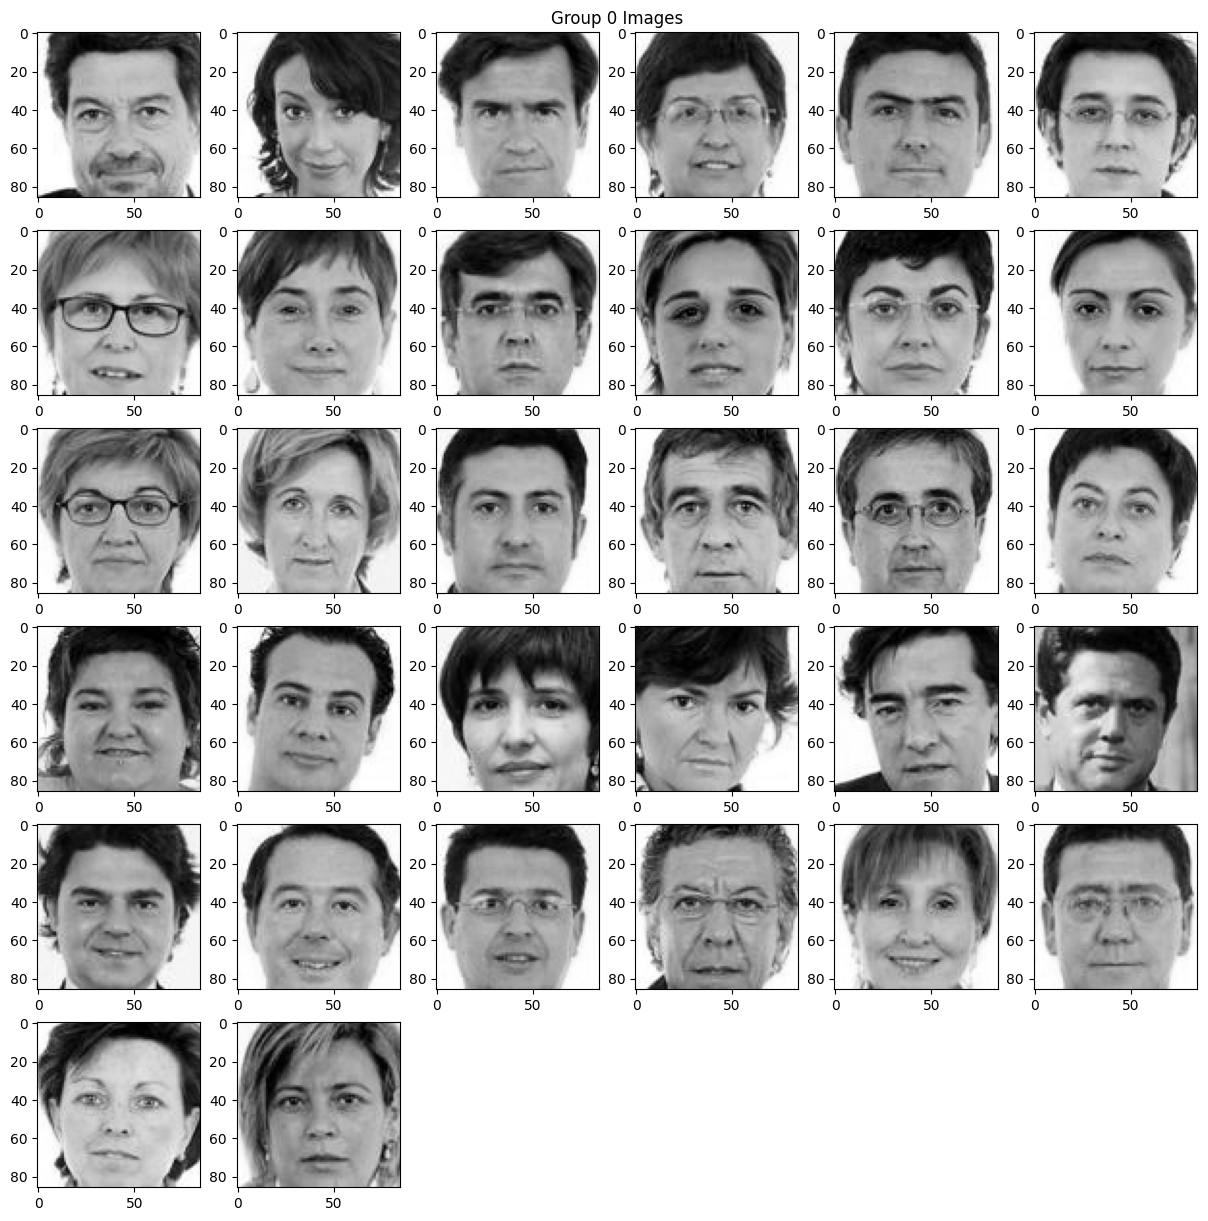

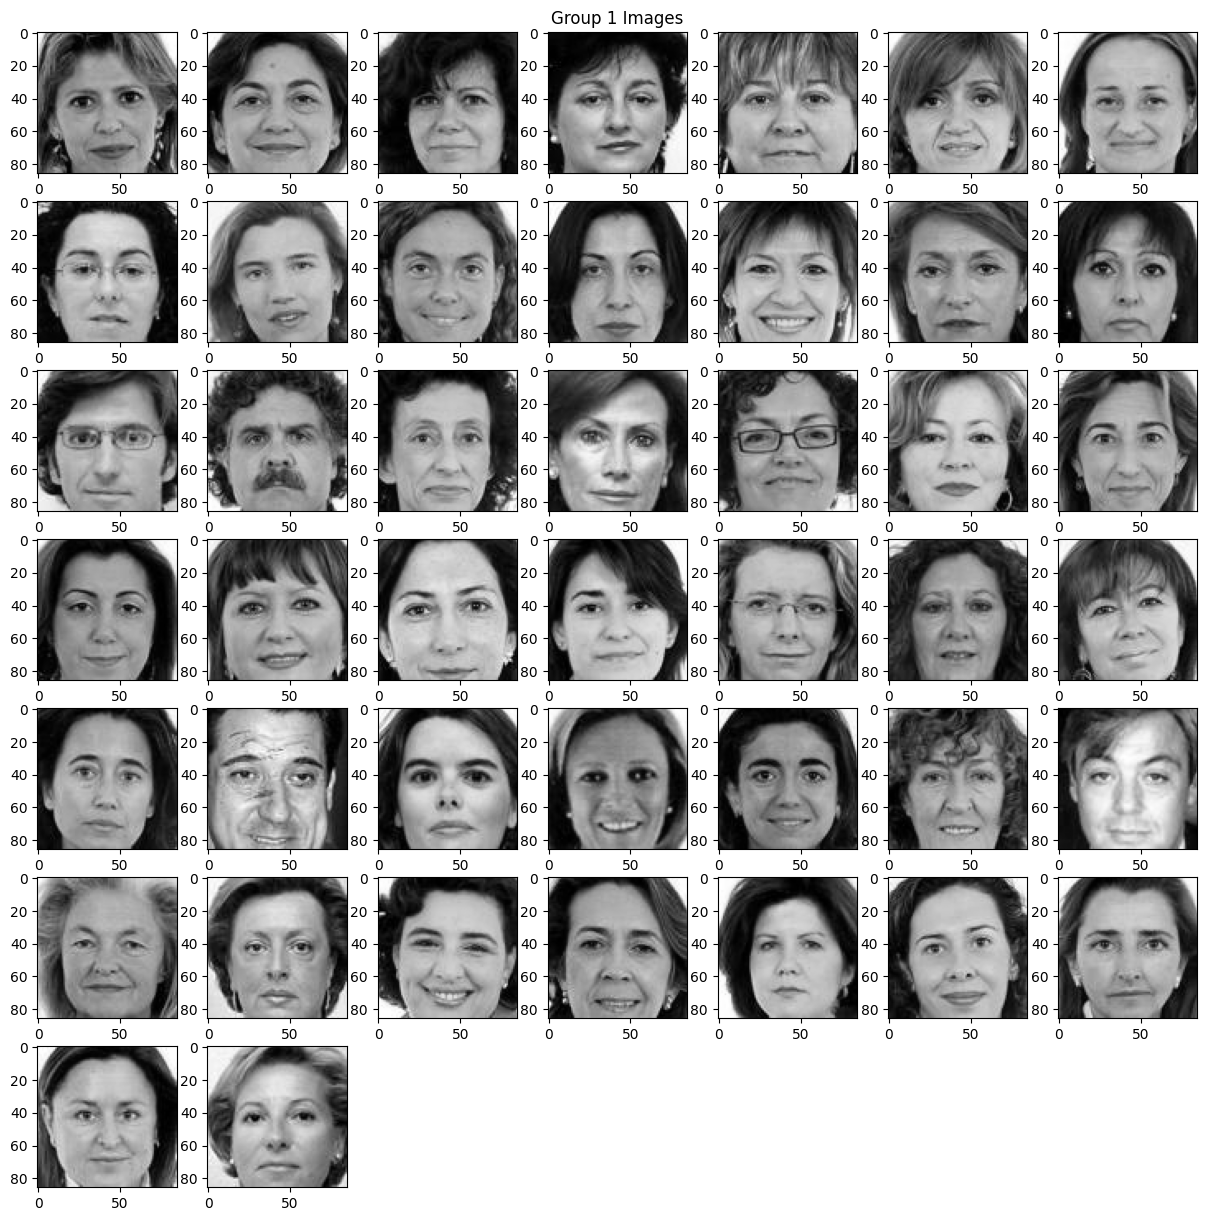

In [35]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=10, random_state=42) 
kmeans.fit(X)
labels = kmeans.labels_


def plot_group_images(group_label, image_shape):
    """This function plots images for a specific group."""
    group_indices = np.where(labels == group_label)[0]
    num_images = len(group_indices)
    
    # Determine the number of rows and columns for the subplot grid
    cols = int(np.ceil(np.sqrt(num_images)))
    rows = int(np.ceil(num_images / cols))
    
    plt.figure(figsize=(15, 15))
    plt.title(f'Group {group_label} Images')
    plt.axis('off')
    for i, idx in enumerate(group_indices):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X[idx].reshape(image_shape), cmap='gray')
        
    
    plt.show()


# Assuming the original images were 86x85 pixels
image_shape = (86, 85)

# Plot images for two groups of your choice (e.g., group 0 and group 1)
plot_group_images(0, image_shape)
plot_group_images(1, image_shape)

It is interesting, that you can already see that the people in the first two groups look similar to each other. A lot of people from the first group have short dark hair and an exposed forehead while most people in the second group are females with the hair filling all four corners of the image. Even two of the four men assigned to this group have longer hair. 

Let's check how many representatives we have per cluster.

[32 44 42 38 28 49 24 32 41 18]


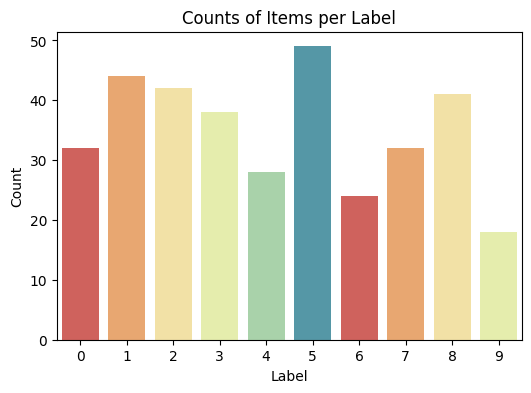

In [36]:
# Count the items per label
label_counts = np.bincount(labels)
print(label_counts)
# Create a DataFrame for plotting
label_df = pd.DataFrame({'Label': np.arange(len(label_counts)), 'Count': label_counts})

# Plot the bar plot
plt.figure(figsize=(6, 4))
sns.barplot(x='Label', y='Count', data=label_df, palette=spanish_palette)
plt.title('Counts of Items per Label')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

Now let's see how many men and women we have per group.

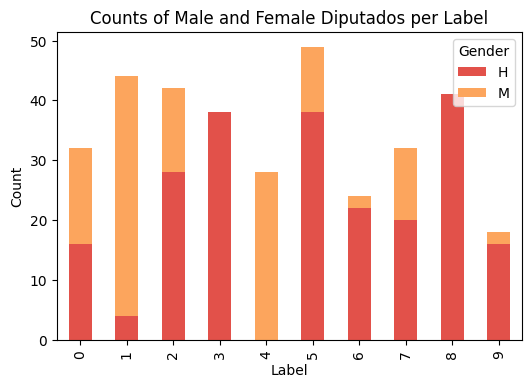

In [37]:
# Create a DataFrame with labels and genders
label_gender_df = pd.DataFrame({'Label': labels, 'Gender': Yg})

label_gender_counts = label_gender_df.groupby(['Label', 'Gender']).size().unstack(fill_value=0)

label_gender_counts.plot(kind='bar', stacked=True, figsize=(6, 4), color=spanish_palette[:2])
plt.title('Counts of Male and Female Diputados per Label')
plt.xlabel('Label')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()


#### <i style="color:grey">5. Plot the centroid corresponding to each k-means cluster (10 images corresponding to the mean of each cluster)

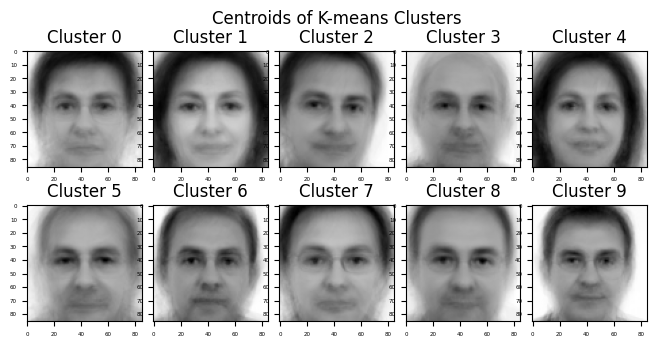

In [38]:
centroids = kmeans.cluster_centers_

image_shape = (86, 85)

# plot the centroids
plt.figure(figsize=(8, 4))
plt.axis('off')
plt.title('Centroids of K-means Clusters')
for i, centroid in enumerate(centroids):
    plt.subplot(2, 5, i + 1)
    plt.imshow(centroid.reshape(image_shape), cmap='gray')
    # plt.axis('off')
    plt.tick_params(axis='both', which='major', labelsize=4)
    plt.title(f'Cluster {i}')

plt.subplots_adjust(wspace=0.1, hspace=0.01)
plt.show()


Now this alligns quite well with the plot we saw before on the gender distribution. The centroid face of cluster 1 and 4 clearly looks like a woman, because these clusters mainly or completely contain women. Something I noticed in group 0 too is the amount of spectacle carriers, which seems to be quite large in cluster 8 and cluster 9 too. 

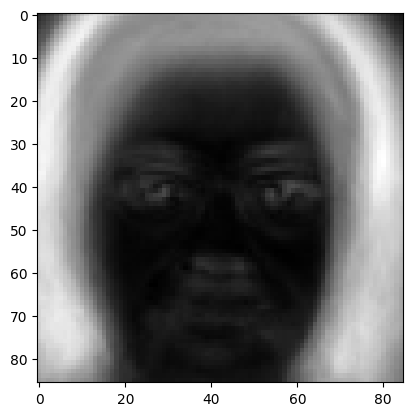

In [ ]:
# centroids = kmeans.cluster_centers_
# centroids.mean(axis=0).reshape(86, 85)

# plt.imshow(centroids.mean(axis=0).reshape(86, 85), cmap='gray')

# plt.imshow(centroids.std(axis=0).reshape(86, 85), cmap='gray')


#### <i style="color:grey">6. Fit a PCA model of the dataset.

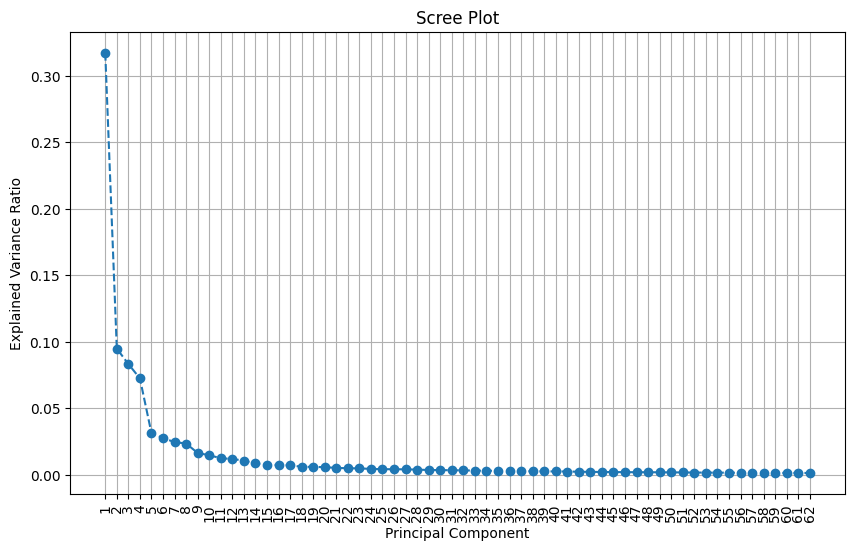

Explained variance ratio: [0.31706522 0.09483614 0.08328332 0.0724765  0.03131165 0.02762453
 0.02456081 0.02351902 0.01642834 0.01468067 0.01250964 0.01186884
 0.01069778 0.00856952 0.0076401  0.00735352 0.00714784 0.00606145
 0.0059685  0.00574905 0.00518976 0.00494577 0.00481628 0.00444013
 0.00424411 0.00417173 0.0041099  0.0038891  0.00361591 0.00353364
 0.00342447 0.00333869 0.00315049 0.00310217 0.00296143 0.00283034
 0.00275849 0.00264994 0.00258107 0.00253455 0.00247266 0.0023137
 0.00219607 0.00213028 0.00204917 0.00199226 0.00193718 0.001934
 0.00189059 0.00182584 0.00176695 0.00170902 0.00165679 0.00162599
 0.00161354 0.00156337 0.00153066 0.00151115 0.00145565 0.00143901
 0.00141797 0.00137781]
Number of components: 62


In [39]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.9, random_state=42) # because the last 200 components are not very useful, jsut explain 90% of the variance
X_pca = pca.fit_transform(X)

# let's draw a screeplot to see what makes sense here
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(np.arange(1, len(pca.explained_variance_ratio_) + 1), rotation=90)
plt.grid()
plt.show()

# Print the explained variance ratio
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Number of components:", pca.n_components_)

We can see that after the first component, there is already a large drop in explained variance. This is almost normal but then after the first 4, or at the most 8 components the added amount of variance explained is very small. 62 components explain 90% of the variance in total. Not setting this threshold would result in more than 300 components, which does not make sense.

#### <i style="color:grey">7. Build a 2D score plot with the projections of the representatives onto the PCA plane. Generate two plots, one marking the gender label, a second one marking the political afiliation label,.

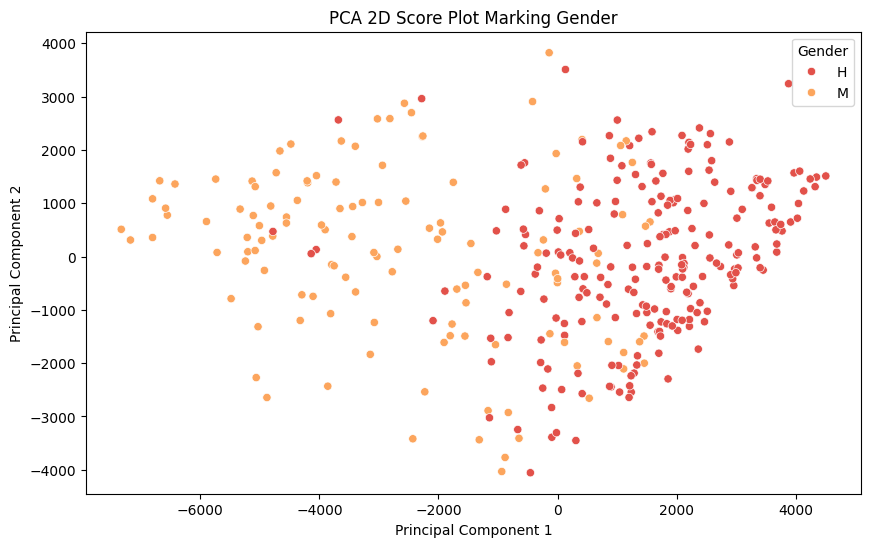

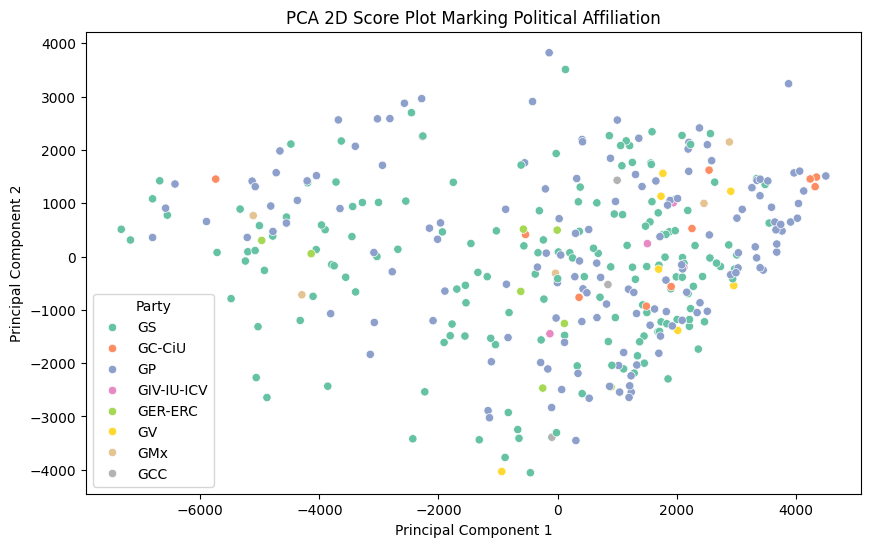

In [43]:
# First I need to select the first two components and then add the feature labels to the DataFrame
df_pca = pd.DataFrame(X_pca[:, 0:2], columns=['PC1', 'PC2'])
df_pca['Gender'] = Yg
df_pca['Party'] = Yp

# Plot 1: Marking the gender label
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Gender', palette=spanish_palette)
plt.title('PCA 2D Score Plot Marking Gender')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Gender')
plt.show()

# Plot 2: Marking the political affiliation label
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Party', palette='Set2')
plt.title('PCA 2D Score Plot Marking Political Affiliation')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Party')
plt.show()

There is quite a clear cluster difference between men and women between the first and second component, but as expected, not such a clear distinguishment between the political parties. 

Let's see how the average first few components look like. 

#### <i style="color:grey">8. Plot the first three eigenvectors (principal components, PCs) projection vectors.

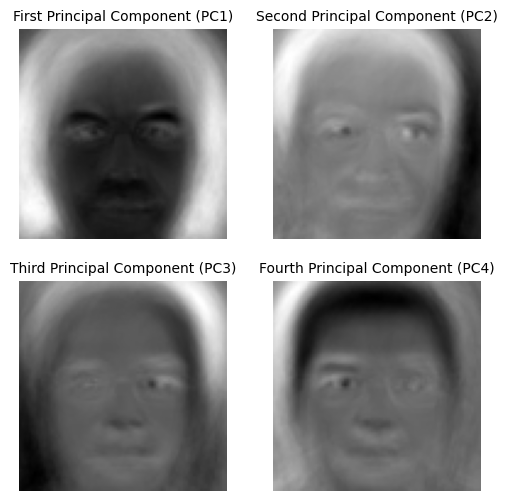

In [44]:
# Extract the first and second principal components
pc1 = pca.components_[0]
pc2 = pca.components_[1]
pc3 = pca.components_[2]
pc4 = pca.components_[3]

image_shape = (86, 85)

# Reshape and plot the first four principal components
pc1_image = pc1.reshape(image_shape)
pc2_image = pc2.reshape(image_shape)
pc3_image = pc3.reshape(image_shape)
pc4_image = pc4.reshape(image_shape)

fig, ax = plt.subplots(2, 2, figsize=(6, 6))
ax[0, 0].imshow(pc1_image, cmap='gray')
ax[0, 0].set_title('First Principal Component (PC1)', fontsize=10)
ax[0, 0].axis('off')

ax[0, 1].imshow(pc2_image, cmap='gray')
ax[0, 1].set_title('Second Principal Component (PC2)', fontsize=10)
ax[0, 1].axis('off')

ax[1, 0].imshow(pc3_image, cmap='gray')
ax[1, 0].set_title('Third Principal Component (PC3)', fontsize=10)
ax[1, 0].axis('off')

ax[1, 1].imshow(pc4_image, cmap='gray')
ax[1, 1].set_title('Fourth Principal Component (PC4)', fontsize=10)
ax[1, 1].axis('off')

plt.show()


Can we see any structure if we do not reshape the features to images?

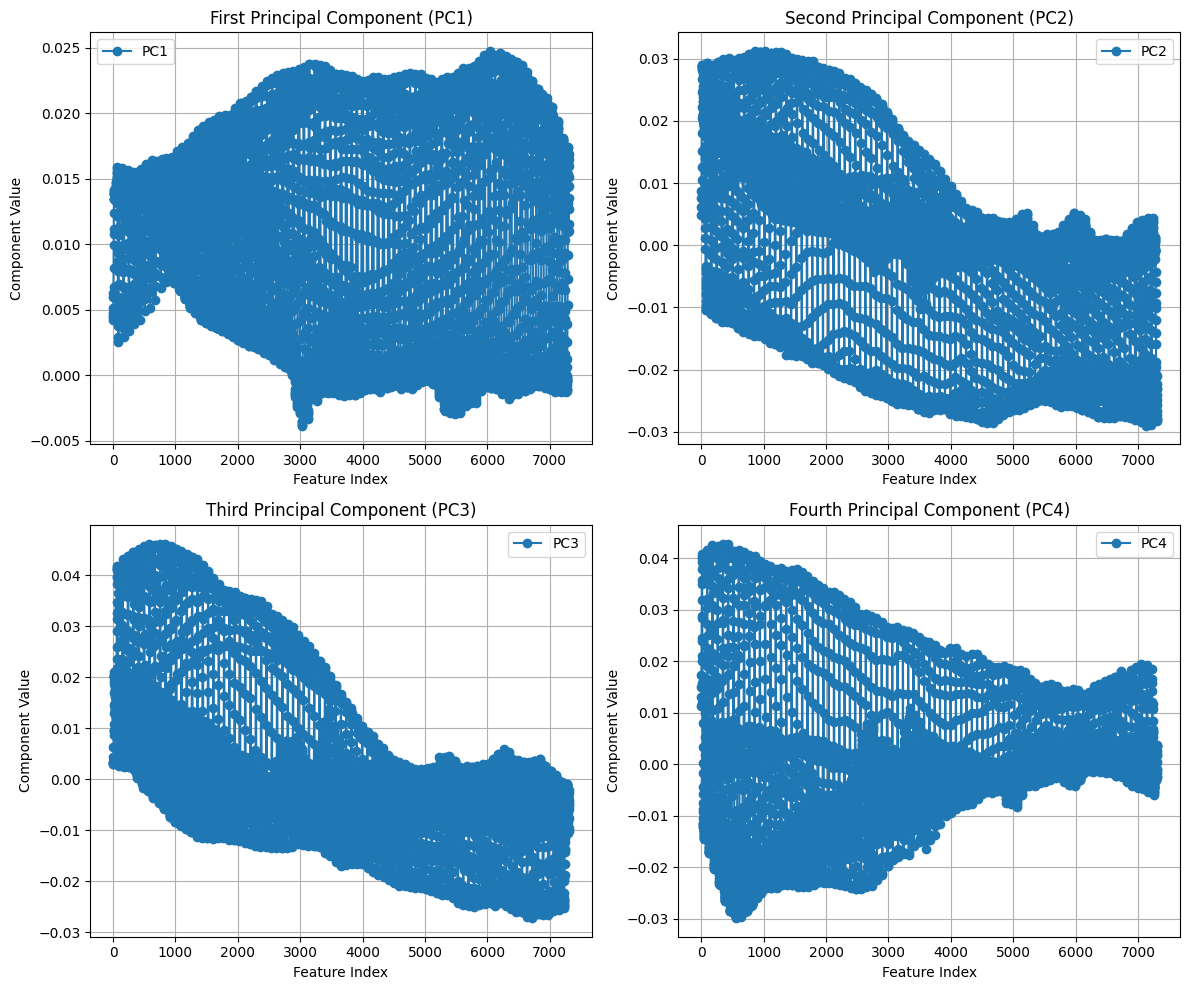

In [45]:
# Plot the first four principal components as vectors
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.plot(pc1, marker='o', linestyle='-', label='PC1')
plt.title('First Principal Component (PC1)')
plt.xlabel('Feature Index')
plt.ylabel('Component Value')
plt.legend()
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(pc2, marker='o', linestyle='-', label='PC2')
plt.title('Second Principal Component (PC2)')
plt.xlabel('Feature Index')
plt.ylabel('Component Value')
plt.legend()
plt.grid()

plt.subplot(2, 2, 3)
plt.plot(pc3, marker='o', linestyle='-', label='PC3')
plt.title('Third Principal Component (PC3)')
plt.xlabel('Feature Index')
plt.ylabel('Component Value')
plt.legend()
plt.grid()

plt.subplot(2, 2, 4)
plt.plot(pc4, marker='o', linestyle='-', label='PC4')
plt.title('Fourth Principal Component (PC4)')
plt.xlabel('Feature Index')
plt.ylabel('Component Value')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

#### <i style="color:grey">9. Do you observe any instrumental variance (not due to the observed nature, but to the observation process)? 

In the first four component vectors plotted as images, we can see some common differences. Higher values mean a better score for that component, which means more similarities for that feature which is reflected in higher grayscale values both negative and positive. So we can see that PC1 has a lot of members with a lot of hair, since the area around the face is glooming white. Since, looking at the PC1/PC2 by gender plot, most women have a negative score for PC1, this could be reflected as the inverse. 

The face of the figure in PC2 seems to be shifted to the left a bit. This could be the group of people who do not have a "passport-like" photo of themselves but rather a side-angel one. 

PC3 has a light line marking glasses which could be one commonality in this component. While the hair for group 4 is really dark, indicating low scores in this feature. 

#### <i style="color:grey">10. Plot the amount of variance explained by each PCs

Originally, I had this screeplot right away when I ran the PCA algorithm. To decide how many components might be useful to have. Some comments on the amount of explained variance can also be found above. In short, first eight components explain the most variance and after that each further component has little significant contribution. 62 components explain 90% of the variance. 

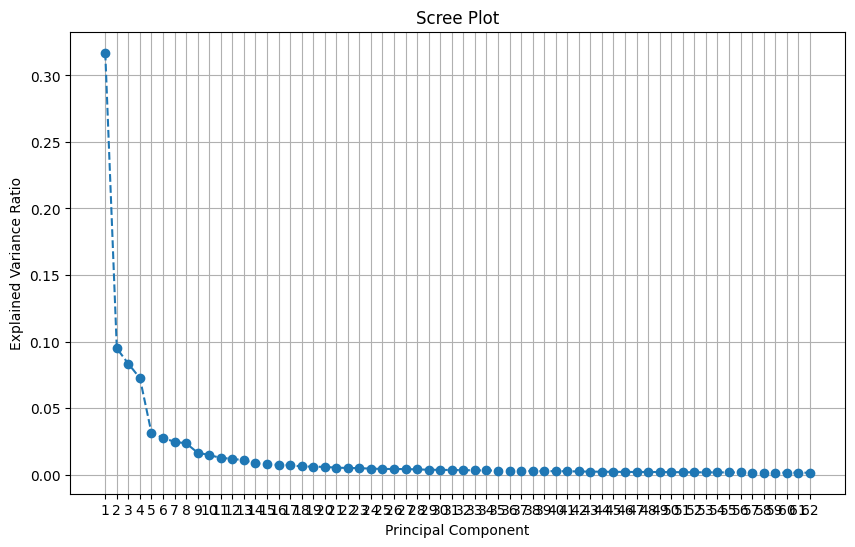

In [46]:
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(np.arange(1, len(pca.explained_variance_ratio_) + 1))
plt.grid()
plt.show()

#### <i style="color:grey"><i style="color:grey">11. Train a gender predictor  with the class of representatives. Which performance can you get on predicting gender from the images? Provide metrics.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
Yg_encoded = le.fit_transform(Yg)

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Yg_encoded, test_size=0.25, random_state=42)

Now we train the classifier - here I pick a randomforest but it might also be interesting to try CNNs or Support Vector Machines. Let's see if there is time for that. 

I pick 0.25/0.75 as a test/train split because that would give me 85 images in the test set which makes sure we get enough women in the training data. But to be sure, let's check that before we start training. 
If by some small chance, we get no women in the training split, we will have a classical case of "algorithmic discrimination". 

In [48]:
from collections import Counter

def print_distribution(labels, label_encoder, dataset_name):
    counter = Counter(labels)
    total = sum(counter.values())
    print(f'Distribution in {dataset_name}:')
    for label, count in counter.items():
        gender = label_encoder.inverse_transform([label])[0]
        print(f'{gender}: {count} ({count / total:.2%})')
    print()

# Print the distribution in the whole dataset
print_distribution(Yg_encoded, le, 'Whole Dataset')

# Print the distribution in the training set
print_distribution(Y_train, le, 'Training Set')

# Print the distribution in the testing set
print_distribution(Y_test, le, 'Testing Set')

Distribution in Whole Dataset:
H: 223 (64.08%)
M: 125 (35.92%)

Distribution in Training Set:
M: 91 (34.87%)
H: 170 (65.13%)

Distribution in Testing Set:
M: 34 (39.08%)
H: 53 (60.92%)



So that looks quite good. I reckon the risk would be way bigger, if we would have a parliament of say 95% men and 5% women. 

In [49]:
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, Y_train)

RandomForestClassifier(random_state=42)

Accuracy: 0.87
Classification Report:
              precision    recall  f1-score   support

           H       0.88      0.92      0.90        53
           M       0.87      0.79      0.83        34

    accuracy                           0.87        87
   macro avg       0.87      0.86      0.86        87
weighted avg       0.87      0.87      0.87        87



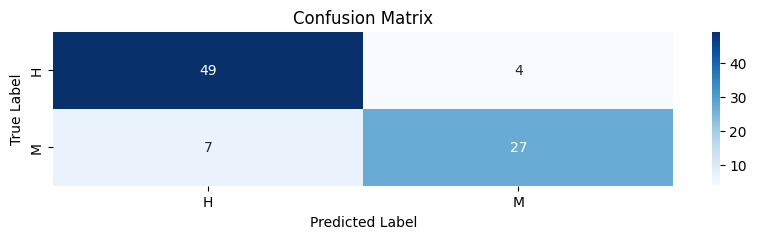

In [50]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# predict on the test set
Y_pred = clf.predict(X_test)

# calculate performance metrics
accuracy = accuracy_score(Y_test, Y_pred)
conf_matrix = confusion_matrix(Y_test, Y_pred)
class_report = classification_report(Y_test, Y_pred, target_names=le.classes_)

print(f'Accuracy: {accuracy:.2f}')
# print('Confusion Matrix:')
# print(conf_matrix)
print('Classification Report:')
print(class_report)

# plot the confusion matrix as heat map
plt.figure(figsize=(10, 2))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

#### <i style="color:grey">11. Do the same with the label containing political party of the representatives. Discuss the results. 

In [52]:
le_party = LabelEncoder()
Yp_encoded = le_party.fit_transform(Yp)

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Yp_encoded, test_size=0.25, random_state=42)

In [53]:
# Function to print the distribution of political party labels
def print_distribution(labels, label_encoder, dataset_name):
    counter = Counter(labels)
    total = sum(counter.values())
    print(f'Distribution in {dataset_name}:')
    for label, count in counter.items():
        party = label_encoder.inverse_transform([label])[0]
        print(f'{party}: {count} ({count / total:.2%})')
    print()

# Print the distribution in the whole dataset
print_distribution(Yp_encoded, le_party, 'Whole Dataset')

# Print the distribution in the training set
print_distribution(Y_train, le_party, 'Training Set')

# Print the distribution in the testing set
print_distribution(Y_test, le_party, 'Testing Set')

Distribution in Whole Dataset:
GS: 164 (47.13%)
GC-CiU: 10 (2.87%)
GP: 146 (41.95%)
GIV-IU-ICV: 5 (1.44%)
GER-ERC: 8 (2.30%)
GV: 7 (2.01%)
GMx: 5 (1.44%)
GCC: 3 (0.86%)

Distribution in Training Set:
GP: 115 (44.06%)
GS: 116 (44.44%)
GC-CiU: 9 (3.45%)
GV: 6 (2.30%)
GMx: 3 (1.15%)
GER-ERC: 5 (1.92%)
GIV-IU-ICV: 5 (1.92%)
GCC: 2 (0.77%)

Distribution in Testing Set:
GP: 31 (35.63%)
GS: 48 (55.17%)
GMx: 2 (2.30%)
GCC: 1 (1.15%)
GER-ERC: 3 (3.45%)
GV: 1 (1.15%)
GC-CiU: 1 (1.15%)



Notice, that here we have a small problem. The test set only contains seven different parties, while the other sets have eight. All five members of GIV-IU-ICV landed in the training set. One way to solve this, would just be to randomly resample until all parties land in the test pot, or specify a sampling distribution to reflect the distribution of the whole data set. Or to just ignore it.

In [54]:
# Train a Random Forest classifier
clf_party = RandomForestClassifier(n_estimators=100, random_state=42)
clf_party.fit(X_train, Y_train)

RandomForestClassifier(random_state=42)

Accuracy: 0.57
Classification Report:
              precision    recall  f1-score   support

      GC-CiU       0.00      0.00      0.00         1
         GCC       0.00      0.00      0.00         1
     GER-ERC       0.00      0.00      0.00         3
  GIV-IU-ICV       0.00      0.00      0.00         2
         GMx       0.49      0.65      0.56        31
          GP       0.65      0.62      0.64        48
          GS       0.00      0.00      0.00         1

    accuracy                           0.57        87
   macro avg       0.16      0.18      0.17        87
weighted avg       0.53      0.57      0.55        87



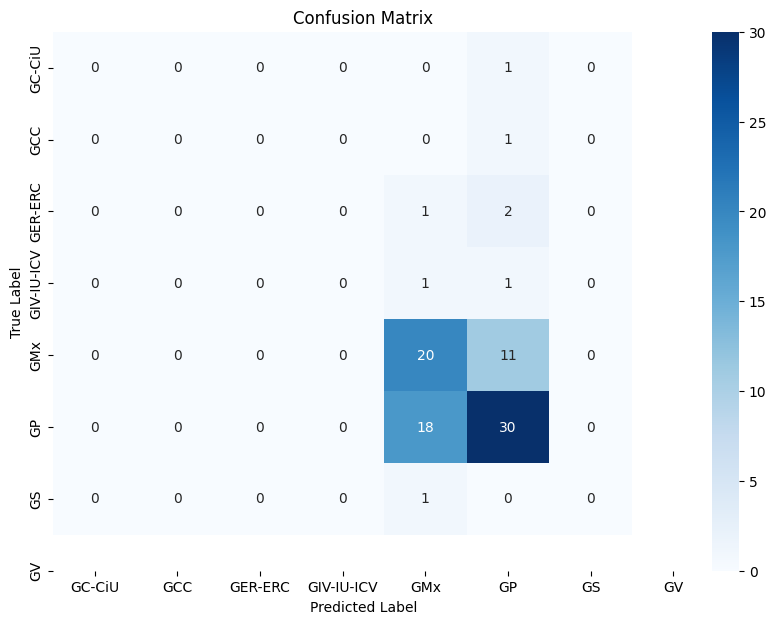

In [55]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predict on the test set
Y_pred_party = clf_party.predict(X_test)

# Calculate performance metrics
accuracy_party = accuracy_score(Y_test, Y_pred_party)
conf_matrix_party = confusion_matrix(Y_test, Y_pred_party)
class_report_party = classification_report(Y_test, Y_pred_party, target_names=le_party.classes_, labels=np.unique(Y_test))

# Print the accuracy
print(f'Accuracy: {accuracy_party:.2f}')

# Print the classification report
print('Classification Report:')
print(class_report_party)

# Plot the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix_party, annot=True, fmt='d', cmap='Blues', xticklabels=le_party.classes_, yticklabels=le_party.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

With an accuracy of 87% for the gender classifier vs 57% for the party classifier, it is fair to say that predicting the gender of an image of a person's face works better than to predict their party. 

In fact looking at the confusion matrix of the party classifier, we can see that all of the correct classifications are just luck, since our classifier is generalized so much, that is simply classifies all images to either one of the two major parties GMx and GP. Another classical case if the classes in the training set are very unevenly distributed. 

At first I thought using less pruned trees might lead to more classifications for the other parties with a trade-off for overfitting, but then again, there is simply no feature in an unseen image, that could make the classifier predict the party of that person. Unless we have twins or siblings both representing the same party :D

### Bonus Questions:

#### <i style="color:lightblue">1. With the PCA model, being e1 and e2 the fist and second eigenvector and μ the mean image, reconstruct a synthetic  image generated on the PCA plane:

$$
\vec{I} = \mu + A \cdot \vec{e}_1 + B \cdot \vec{e}_2
$$
#### where $A$ and $B$ are two scalars.

#### Build an interactive plot that generates the reconstructed image from A and B through two sliders.  

In [56]:
# just for safety I will run the PCA again and compute the mean image
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

mean_image = X.mean(axis=0)

# first and second principal components
e1 = pca.components_[0]
e2 = pca.components_[1]

# and as always the image shape
image_shape = (86, 85)

In [172]:
e2

array([ 0.00486138,  0.00613331,  0.00755896, ..., -0.02289321,
       -0.02223628, -0.0211037 ])

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# define a function to update the plot based on slider values
def update_image(A, B):
    reconstructed_image = mean_image + A * e1 + B * e2
    reconstructed_image = reconstructed_image.reshape(image_shape)
    
    plt.figure(figsize=(6, 6))
    plt.imshow(reconstructed_image, cmap='gray')
    plt.title(f'Reconstructed Image\nA={A}, B={B}')
    plt.axis('off')
    plt.show()

# sliders for A and B with adjusted width
A_slider = widgets.FloatSlider(value=0, min=-5000, max=5000, step=10, description='A', layout=widgets.Layout(width='600px'))
B_slider = widgets.FloatSlider(value=0, min=-5000, max=5000, step=10, description='B', layout=widgets.Layout(width='600px'))

# interactive plot
widgets.interactive(update_image, A=A_slider, B=B_slider)

interactive(children=(FloatSlider(value=0.0, description='A', layout=Layout(width='600px'), max=5000.0, min=-5…

Somehow, and maybe because the scores in the components are so low, changes can only really be seen if the scalars are set to really high levels (1000 and higher).

But what is really interesting to see is that the first component does in fact seem to explain gender. Having the slider at -5000 makes the image look more like a woman while +5000 look like an elderly man. 

The second component with scalar B shifts the faces to the left or to the right. Maybe this explains the angle of the picture taken.

#### <i style="color:lightblue">2. Use PCA as a compression algorithm. Check the effect of the compression with the number of PCs. Is the method usefull also in cross validation? 

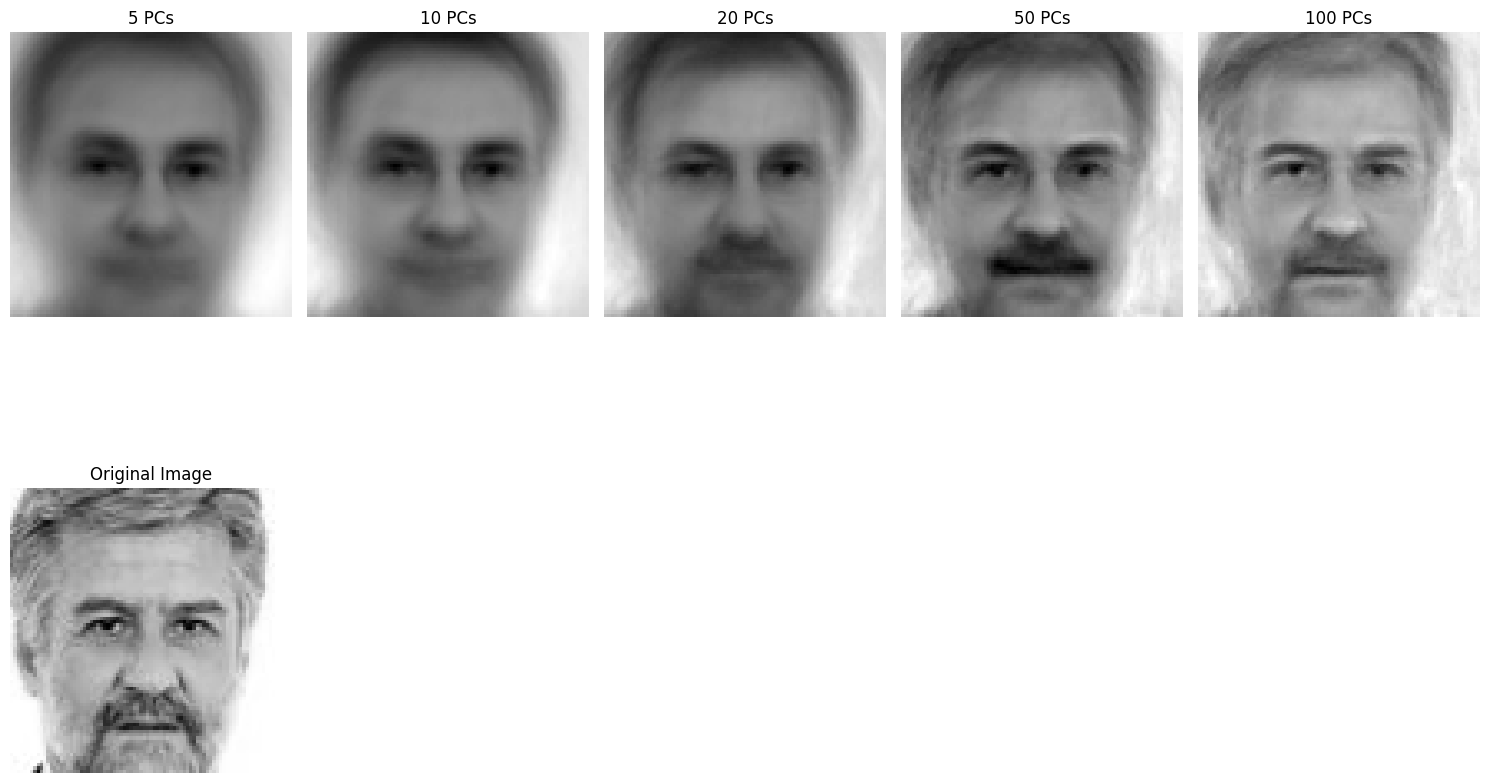

In [177]:
from sklearn.decomposition import PCA

def reconstruct_image(X, n_components):
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X)
    X_reconstructed = pca.inverse_transform(X_pca)
    return X_reconstructed

image_shape = (86, 85)

# number of components to test
components_list = [5, 10, 20, 50, 100]

plt.figure(figsize=(15, 10))
for i, n_components in enumerate(components_list):
    X_reconstructed = reconstruct_image(X, n_components)
    reconstructed_image = X_reconstructed[0].reshape(image_shape)
    
    plt.subplot(2, len(components_list), i + 1)
    plt.imshow(reconstructed_image, cmap='gray')
    plt.title(f'{n_components} PCs')
    plt.axis('off')

# plot of the original image for comparison
original_image = X[0].reshape(image_shape)
plt.subplot(2, len(components_list), len(components_list) + 1)
plt.imshow(original_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

One can tell, that although up to ten principal components explain most of the variance, the compression becomes so intensive that it is no longer possible to recognise the Diputado's face and that to distuingish him clearly, more components are necessary.

In [176]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

# Define a pipeline with PCA and a classifier
pipeline = Pipeline([
    ('pca', PCA(n_components=20, random_state=42)),  # Adjust n_components as needed
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Perform cross-validation
scores = cross_val_score(pipeline, X, Yg_encoded, cv=5, scoring='accuracy')

# Print the cross-validation scores
print('Cross-validation scores:', scores)
print('Mean cross-validation score:', np.mean(scores))

Cross-validation scores: [0.88571429 0.88571429 0.95714286 0.88405797 0.89855072]
Mean cross-validation score: 0.9022360248447205


#### <i style="color:lightblue">3. Use BS4 (https://pypi.org/project/bs4/) or scrapy (https://scrapy.org) to download your own dataset from https://www.congreso.es/hemiciclo 